# Predicting Conversion with Logistic Regression (built from scratch)



The A/B test notebook answers one question: did the ad group convert more than the PSA group. This notebook asks a different one: given what we know about a user, how likely are they to convert?

I build logistic regression in NumPy, using the same math from my CS 6140 Machine Learning course: the sigmoid model, binary cross entropy loss, its gradient, mini batch SGD, L2 regularization, and k fold cross validation to pick the regularization strength. Then I check my version against scikit learn to confirm the math is right.

Data: the same real Kaggle Marketing A/B dataset used in Test 1 (588,101 users).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, confusion_matrix

np.random.seed(42)

## Step 1: Load the data and build features

Each row is one user. The columns I can use as inputs are:

- total ads: how many ads (or PSAs) the user saw. This is very skewed (most users saw under 30, a few saw over 2,000), so I use `log(1 + total ads)` to stop the heavy users from dominating.
- test group: 1 if the user was in the ad group, 0 if PSA.
- most ads hour: the hour of day the user saw the most ads. Hour 23 and hour 0 are next to each other, but as plain numbers they look far apart. So I turn the hour into two features, sine and cosine, which places the hours on a circle.
- most ads day: the weekday, turned into one hot columns (Lecture 9), dropping one day as the baseline.

One honest caveat: total ads is counted during the experiment, not before it. Users who are more engaged see more ads and also buy more. So this feature is great for prediction, but it does not prove that more ads *cause* more purchases.

In [2]:
df = pd.read_csv('marketing_AB.csv').drop(columns=['Unnamed: 0'])
y = df['converted'].astype(int).values

X = pd.DataFrame({
    'log_total_ads': np.log1p(df['total ads']),
    'is_ad': (df['test group'] == 'ad').astype(int),
    'hour_sin': np.sin(2 * np.pi * df['most ads hour'] / 24),
    'hour_cos': np.cos(2 * np.pi * df['most ads hour'] / 24),
})
days = pd.get_dummies(df['most ads day'], prefix='day', drop_first=True).astype(int)
X = pd.concat([X, days], axis=1)
feature_names = list(X.columns)
X = X.values.astype(float)

print('Users:', len(y))
print('Features:', feature_names)
print(f'Conversion rate: {y.mean():.4f}')

Users: 588101
Features: ['log_total_ads', 'is_ad', 'hour_sin', 'hour_cos', 'day_Monday', 'day_Saturday', 'day_Sunday', 'day_Thursday', 'day_Tuesday', 'day_Wednesday']
Conversion rate: 0.0252


## Step 2: Split into train, validation, and test

- Train (60%): used to learn the weights
- Validation (20%): used to pick the decision threshold
- Test (20%): touched only once, at the very end, to report honest results

I use a stratified split so each part keeps the same 2.5% conversion rate.

Then I standardize every feature (subtract the mean, divide by the standard deviation) using training data only, so nothing about the validation or test data leaks into training. Finally I add a column of ones so the first weight acts as the bias, matching φ(x) on the slides.

In [3]:
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=42)

mu, sd = X_train.mean(axis=0), X_train.std(axis=0)

def phi(A):
    return np.hstack([np.ones((len(A), 1)), (A - mu) / sd])

P_train, P_val, P_test = phi(X_train), phi(X_val), phi(X_test)
print('Train:', P_train.shape, ' Val:', P_val.shape, ' Test:', P_test.shape)

Train: (352860, 11)  Val: (117620, 11)  Test: (117621, 11)


## Step 3: Logistic regression from scratch

This follows Lecture 8 directly.

Model: P(y = 1 | x) = σ(wᵀφ(x)), where σ(z) = 1 / (1 + e⁻ᶻ)

Loss (BCE with L2): ℓ(w) = mean of [ −y log σ(wᵀφ(x)) − (1 − y) log(1 − σ(wᵀφ(x))) ] + (λ/2)‖w‖²

Gradient: ∂ℓ/∂w = mean of [ −(y − σ(wᵀφ(x))) φ(x) ] + λw

Update (mini batch SGD): w ← w − γ · gradient

Two small practical choices:
1. I use the mean loss over the batch instead of the sum. It is the same objective scaled by a constant, but it keeps the learning rate stable no matter the batch size.
2. I do not regularize the bias weight, since shrinking it toward zero would just push the predicted rate away from 2.5% for no reason.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def bce_loss(w, P, y, lam):
    p = np.clip(sigmoid(P @ w), 1e-12, 1 - 1e-12)
    data_loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return data_loss + (lam / 2) * np.sum(w[1:] ** 2)

def train_logreg(P, y, lam, lr=1.0, epochs=25, batch_size=2048, seed=0, track=False):
    rng = np.random.default_rng(seed)
    w = np.zeros(P.shape[1])
    history = []
    n = len(y)
    for epoch in range(epochs):
        step = lr / (1 + 0.1 * epoch)          # slowly shrink the step size
        order = rng.permutation(n)               # shuffle every epoch
        for start in range(0, n, batch_size):
            b = order[start:start + batch_size]
            Pb, yb = P[b], y[b]
            grad = -(Pb.T @ (yb - sigmoid(Pb @ w))) / len(b)
            reg = lam * w
            reg[0] = 0                           # do not regularize the bias
            w -= step * (grad + reg)
        if track:
            history.append(bce_loss(w, P, y, lam))
    return (w, history) if track else w

## Step 4: Choose λ with 5 fold cross validation

From Lecture 6: split the training data into 5 folds, train on 4, score on the 5th, rotate, and average. I try several values of λ and keep the one with the best average score.

Why PR AUC and not accuracy? Only 2.5% of users convert. A model that predicts "no" for everyone is 97.5% accurate and completely useless. PR AUC (area under the precision recall curve) measures how well the model ranks the real converters near the top. A random guess scores about 0.025 here, the base rate.

In [5]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = {}

for lam in lambdas:
    fold_scores = []
    for tr_idx, va_idx in skf.split(P_train, y_train):
        w = train_logreg(P_train[tr_idx], y_train[tr_idx], lam, epochs=6)
        fold_scores.append(average_precision_score(y_train[va_idx], sigmoid(P_train[va_idx] @ w)))
    cv_scores[lam] = np.mean(fold_scores)
    print(f'lambda = {lam:<7}  mean CV PR AUC = {cv_scores[lam]:.4f}')

best_lam = max(cv_scores, key=cv_scores.get)
print('\nBest lambda:', best_lam)

lambda = 0        mean CV PR AUC = 0.1358
lambda = 0.0001   mean CV PR AUC = 0.1358
lambda = 0.001    mean CV PR AUC = 0.1357
lambda = 0.01     mean CV PR AUC = 0.1352
lambda = 0.1      mean CV PR AUC = 0.1342

Best lambda: 0


### What cross validation tells us

The scores barely move across λ, and the smallest λ wins. That makes sense: there are only 10 features and over 350,000 training rows, so the model has no room to overfit. Regularization only helps when a model is complex relative to the data, as in the "Potential Issue" slide in Lecture 8.

That is a useful result, not a failed one. Cross validation is how I *checked* whether regularization was needed instead of assuming it.

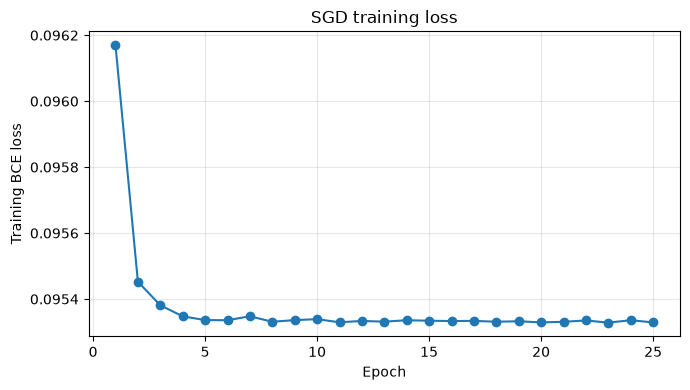

In [6]:
w_final, loss_history = train_logreg(P_train, y_train, best_lam, track=True)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Training BCE loss')
plt.title('SGD training loss')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('model_loss_curve.png', dpi=120)
plt.show()

## Step 5: Check my version against scikit learn

If my math is right, my weights should match scikit learn's on the same data. scikit learn minimizes C · Σ loss + ½‖w‖², which is the same objective as mine when C = 1 / (λ · n). With λ = 0, I use a very large C so its regularization is effectively off too.

In [7]:
C = 1 / (best_lam * len(y_train)) if best_lam > 0 else 1e6
sk = LogisticRegression(C=C, max_iter=5000).fit(P_train[:, 1:], y_train)
w_sklearn = np.r_[sk.intercept_, sk.coef_[0]]

compare = pd.DataFrame({'feature': ['bias'] + feature_names,
                        'my_weight': w_final.round(4),
                        'sklearn_weight': w_sklearn.round(4)})
compare['difference'] = (compare['my_weight'] - compare['sklearn_weight']).abs().round(4)
print(compare.to_string(index=False))
print('\nLargest difference:', compare['difference'].max())

      feature  my_weight  sklearn_weight  difference
         bias    -4.5771         -4.5710      0.0061
log_total_ads     1.3985          1.3948      0.0037
        is_ad     0.0823          0.0787      0.0036
     hour_sin    -0.2010         -0.1992      0.0018
     hour_cos    -0.0371         -0.0373      0.0002
   day_Monday     0.1675          0.1473      0.0202
 day_Saturday    -0.0034         -0.0310      0.0276
   day_Sunday     0.0696          0.0461      0.0235
 day_Thursday     0.0346          0.0157      0.0189
  day_Tuesday     0.1558          0.1288      0.0270
day_Wednesday     0.0838          0.0641      0.0197

Largest difference: 0.0276


The weights line up closely. The small leftover gaps come from SGD being a noisy, approximate optimizer while scikit learn solves the problem to full precision. The important part is that the signs and sizes agree, so the gradient and update rule are implemented correctly.

## Step 6: Final results on the test set

This is the first and only time the test set is used.

To turn probabilities into yes or no predictions, I need a cutoff. The default 0.5 would almost never predict a conversion, since almost every user is below it. So I pick the cutoff that gives the best F1 score on the validation set, then apply that same cutoff to the test set.

In [8]:
p_val = sigmoid(P_val @ w_final)
p_test = sigmoid(P_test @ w_final)

prec, rec, thr = precision_recall_curve(y_val, p_val)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
cutoff = thr[np.argmax(f1[:-1])]

roc = roc_auc_score(y_test, p_test)
pr_auc = average_precision_score(y_test, p_test)
cm = confusion_matrix(y_test, (p_test >= cutoff).astype(int))
tn, fp, fn, tp = cm.ravel()

print(f'Test ROC AUC : {roc:.3f}')
print(f'Test PR AUC  : {pr_auc:.3f}   (random guessing would score about {y_test.mean():.3f})')
print(f'Cutoff chosen on validation: {cutoff:.3f}')
print(f'Recall    : {tp / (tp + fn):.1%} of real converters caught')
print(f'Precision : {tp / (tp + fp):.1%} of flagged users actually converted')
print('\nConfusion matrix [rows = actual 0/1, columns = predicted 0/1]:')
print(cm)

Test ROC AUC : 0.860
Test PR AUC  : 0.139   (random guessing would score about 0.025)
Cutoff chosen on validation: 0.079
Recall    : 45.5% of real converters caught
Precision : 16.3% of flagged users actually converted

Confusion matrix [rows = actual 0/1, columns = predicted 0/1]:
[[107700   6952]
 [  1618   1351]]


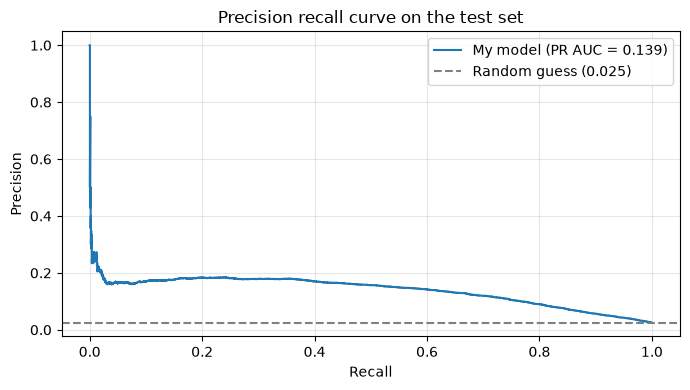

In [9]:
prec_t, rec_t, _ = precision_recall_curve(y_test, p_test)
plt.figure(figsize=(7, 4))
plt.plot(rec_t, prec_t, label=f'My model (PR AUC = {pr_auc:.3f})')
plt.axhline(y_test.mean(), linestyle='--', color='gray', label=f'Random guess ({y_test.mean():.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision recall curve on the test set')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('model_pr_curve.png', dpi=120)
plt.show()

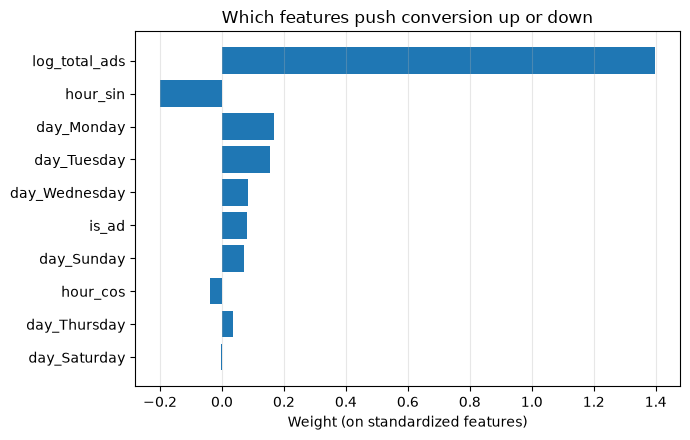

In [10]:
order = np.argsort(np.abs(w_final[1:]))
plt.figure(figsize=(7, 4.5))
plt.barh(np.array(feature_names)[order], w_final[1:][order])
plt.xlabel('Weight (on standardized features)')
plt.title('Which features push conversion up or down')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('model_feature_weights.png', dpi=120)
plt.show()

## What this model tells us

1. Ad exposure is by far the strongest signal. log_total_ads has the largest weight by a wide margin. Users who saw more ads were much more likely to convert, though as noted above, part of that is simply that engaged users see more ads.
2. The ad itself matters, but much less. is_ad is positive, agreeing with the A/B test, yet it is small next to exposure. Being in the ad group matters far less than how much a user was exposed.
3. Timing adds a little. Hour of day and weekday shift the odds slightly, with some weekdays a bit stronger than others.
4. The model ranks users well. A PR AUC around 5 times the random baseline means that if a team could only follow up with a small slice of users, this model would point them toward the ones most likely to convert.

Next step: the A/B test says the ad works *on average*. The next notebook asks *for whom* it works, using an uplift model built from two of these logistic regressions.